# Randomized querying

Query strategies such as query-by-committee or expected error only ask for labels where they
expect the model to be wrong. If the stream drifts where the model is confident, they may never
notice. Žliobaitė et al. (2014) found that randomizing which instances are queried makes active
learning on drifting streams more robust, since every instance then has a chance to be
queried. fishladder offers three ways to randomize any strategy:

- `fl.budget.VariableThreshold(..., randomize=...)` multiplies the threshold by a random factor
  for each instance, as in Žliobaitė et al.'s randomized variable uncertainty.
- `fl.strategy.Split` queries a share of the instances at random, and leaves the rest to the
  strategy.
- `fl.strategy.Randomized` turns the utilities of a strategy into query probabilities.
  Subclasses only define how, with `probability_one`.

This notebook puts them to the test on a drift designed to be hard for deterministic strategies:
a small region of the feature space that changes, and moves back and forth between two points,
with a low budget.

In [1]:
import math
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from river import multioutput, neighbors

import fishladder as fl

## A drift that moves between two points

The stream is a `fl.synth.MultiTarget` with two features and three outputs. After a warm-up of
2000 instances, `y1` changes around one of two points, $(0.25, 0.25)$ and $(0.75, 0.75)$. The
change is a bump of radius about 0.1 that grows, during each visit of 1500 instances, from 0 to
2 standard deviations of `y1`. It then moves to the other point, and the first one goes back to
normal. The drift visits each point twice. `y0` and `y2` do not drift.

The region that changes at any time covers about 3% of the feature space. A strategy has to
find it, and then find it again each time it moves.

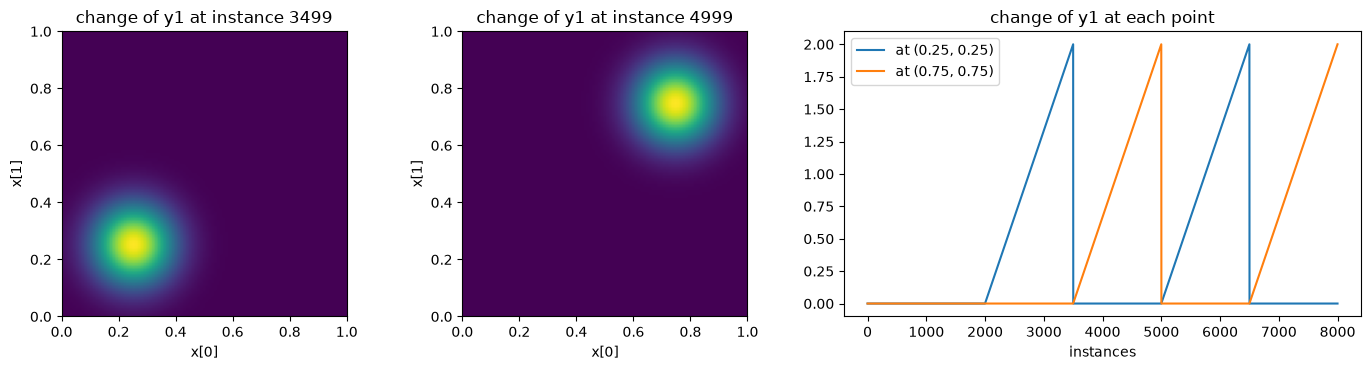

In [2]:
WARMUP, VISIT, N_VISITS = 2000, 1500, 4
N = WARMUP + VISIT * N_VISITS
CENTERS = [(0.25, 0.25), (0.75, 0.75)]
WIDTH, HEIGHT = 0.1, 2.0


def center(t):
    """The point the drift is at, at instance t."""
    if t < WARMUP:
        return None
    return CENTERS[(t - WARMUP) // VISIT % 2]


def change(x, t):
    """How much y1 is moved at x, at instance t."""
    c = center(t)
    if c is None:
        return 0.0
    growth = ((t - WARMUP) % VISIT + 1) / VISIT
    return HEIGHT * growth * math.exp(-(math.dist((x[0], x[1]), c) ** 2) / (2 * WIDTH**2))


def in_focus(x, t):
    """Whether x is in the region that is changing at instance t."""
    c = center(t)
    return c is not None and math.dist((x[0], x[1]), c) <= WIDTH


def stream(seed):
    data = fl.synth.MultiTarget(n_features=2, correlation=0.3, noise=0.1, seed=seed).take(N)
    for t, (x, y) in enumerate(data):
        yield x, {**y, "y1": y["y1"] + change(x, t)}


grid = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), width_ratios=[1, 1, 1.6])
for ax, t in zip(axes, [WARMUP + VISIT - 1, WARMUP + 2 * VISIT - 1]):
    image = [[change({0: a, 1: b}, t) for a in grid] for b in grid]
    ax.imshow(image, origin="lower", extent=(0, 1, 0, 1), vmin=0, vmax=HEIGHT)
    ax.set(title=f"change of y1 at instance {t}", xlabel="x[0]", ylabel="x[1]")
for c in CENTERS:
    axes[2].plot([change({0: c[0], 1: c[1]}, t) for t in range(N)], label=f"at {c}")
axes[2].set(title="change of y1 at each point", xlabel="instances")
axes[2].legend()
fig.tight_layout()

## Strategies

The budget is low: 5% of the labels of each output, with `fl.budget.PerOutput`, so that `y1`
cannot borrow from the other outputs. The models are nearest neighbours on the last 200 labels of
each output, which is about 4000 instances.

The setups are random querying, query-by-committee and expected error, each deterministic strategy
with a variable threshold, and four randomized variants:

- both strategies with a randomized threshold (`randomize=1.0`, as in Žliobaitė et al.);
- expected error with `Split`, which spends a fifth of the budget on random queries;
- expected error with a `Randomized` subclass, `Proportional`, which samples each output with a
  probability proportional to its utility, relative to its recent ones. With `rate`, the
  probabilities are rescaled to what the budget affords, so it needs no threshold.

Expected error gets the most variants because it is the more likely of the two to be blind to a
drift. Its error model only learns from the instances it queried. The committee is already
somewhat randomized, since its members are trained by online bagging.

In [3]:
COSTS = {"y0": 1.0, "y1": 1.0, "y2": 1.0}
RATE = 0.05  # labels per output and instance


def knn():
    return neighbors.KNNRegressor(engine=neighbors.LazySearch(window_size=200))


def budget():
    return fl.budget.PerOutput(fl.budget.RateBudget(RATE * sum(COSTS.values())))


class Proportional(fl.strategy.Randomized):
    """Sample an output with a probability proportional to its utility."""

    def probability_one(self, output, utility, recent):
        return utility / statistics.mean(recent)


def setups(seed):
    def committee():
        return fl.strategy.QueryByCommittee(knn(), seed=seed)

    def expected_error():
        return fl.strategy.ExpectedError(knn())

    def threshold(randomize=0.0):
        return fl.budget.VariableThreshold(budget(), randomize=randomize, seed=seed)

    return {
        "random": (fl.strategy.RandomPerOutput(p=RATE, seed=seed), budget()),
        "committee": (committee(), threshold()),
        "committee, randomized threshold": (committee(), threshold(randomize=1.0)),
        "expected error": (expected_error(), threshold()),
        "expected error, randomized threshold": (expected_error(), threshold(randomize=1.0)),
        "expected error, split": (
            fl.strategy.Split(expected_error(), p=0.2 * RATE, seed=seed),
            threshold(),
        ),
        "expected error, proportional": (
            Proportional(expected_error(), rate=RATE, seed=seed),
            budget(),
        ),
    }

Each setup is run on 10 streams. Every setup sees the same 10 streams, so they can be compared
stream by stream. The log of `y1` is kept, along with where each instance is and whether it was in
the region that was changing at the time. For `y0` and `y2`, only their MAE during the drift is
kept:

In [4]:
SEEDS = range(10)

frames, others = [], {}
for seed in SEEDS:
    data = list(stream(seed))
    for name, (strategy, budget_) in setups(seed).items():
        log = fl.evaluate.prequential(
            data, multioutput.PerOutputRegressor(knn()), strategy, budget_, COSTS
        )
        df = log.to_frame()
        df["error"] = (df["y_true"] - df["y_pred"]).abs()
        rest = df[(df["output"] != "y1") & (df["step"] >= WARMUP)]
        others[name, seed] = rest["error"].mean()
        y1 = df[df["output"] == "y1"].reset_index(drop=True)
        y1["strategy"], y1["seed"] = name, seed
        y1["x0"] = [x[0] for x, _ in data]
        y1["x1"] = [x[1] for x, _ in data]
        y1["focus"] = [in_focus(x, t) for t, (x, _) in enumerate(data)]
        frames.append(y1)
results = pd.concat(frames, ignore_index=True)
drifted = results[results["step"] >= WARMUP]

## Do they find the drift?

During the drift, about 3% of the instances fall in the region that is changing. Random querying
gives it about 3% of the labels. A strategy that finds the drift gives it more:

In [5]:
per_run = drifted.groupby(["strategy", "seed"]).apply(
    lambda d: pd.Series(
        {
            "labels": d["queried"].sum(),
            "labels in focus": d.loc[d["focus"], "queried"].sum(),
            "MAE in focus": d.loc[d["focus"], "error"].mean(),
            "MAE elsewhere": d.loc[~d["focus"], "error"].mean(),
        }
    ),
    include_groups=False,
)
per_run["MAE on y0 and y2"] = pd.Series(others).rename_axis(["strategy", "seed"])
summary = per_run.groupby("strategy").mean()
summary["share in focus"] = summary["labels in focus"] / summary["labels"]
summary.round(3)

,labels,labels in focus,MAE in focus,MAE elsewhere,MAE on y0 and y2,share in focus
strategy,,,,,,
committee,300.1,13.7,0.593,0.187,0.153,0.046
"committee, randomized threshold",299.6,11.4,0.606,0.178,0.147,0.038
expected error,299.2,13.6,0.615,0.188,0.153,0.045
"expected error, proportional",289.5,14.3,0.620,0.175,0.146,0.049
"expected error, randomized threshold",299.5,11.9,0.607,0.177,0.143,0.040
"expected error, split",299.7,13.3,0.608,0.186,0.151,0.044
random,296.8,9.7,0.611,0.182,0.155,0.033


Where the labels of `y1` went during the last visit, for the first stream, with the region that
was changing circled:

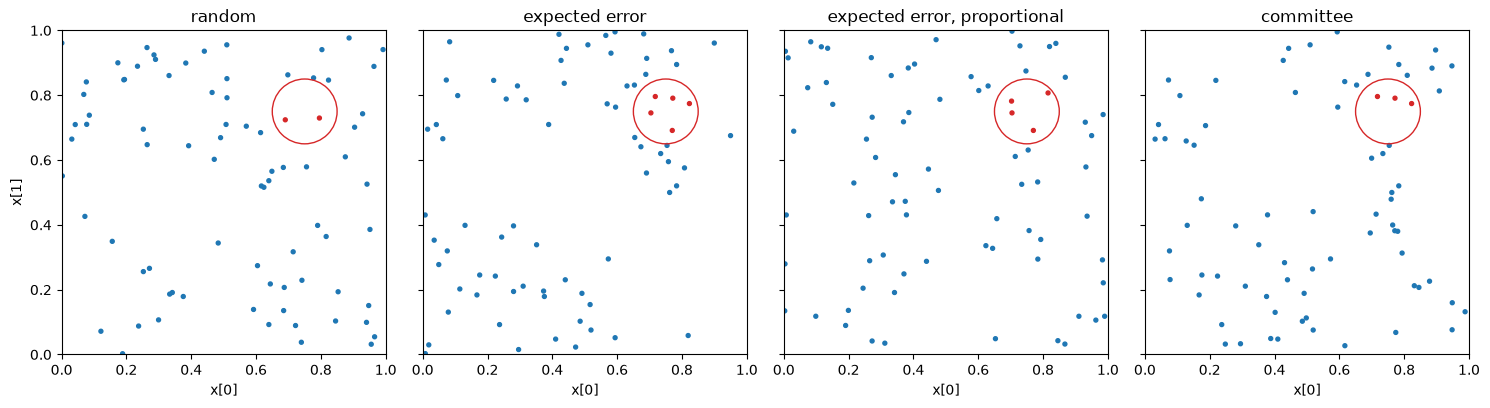

In [6]:
names = ["random", "expected error", "expected error, proportional", "committee"]
last = drifted[(drifted["seed"] == 0) & (drifted["step"] >= N - VISIT) & drifted["queried"]]
fig, axes = plt.subplots(1, len(names), figsize=(15, 3.9), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    q = last[last["strategy"] == name]
    ax.scatter(q["x0"], q["x1"], s=8, c=q["focus"].map({True: "C3", False: "C0"}))
    ax.add_patch(plt.Circle(center(N - 1), WIDTH, fill=False, color="C3"))
    ax.set(title=name, xlabel="x[0]", xlim=(0, 1), ylim=(0, 1), aspect="equal")
axes[0].set_ylabel("x[1]")
fig.tight_layout()

And how many labels each strategy had in the region that was changing, along the stream,
averaged over the 10 streams. The dashed lines are when the drift moves:

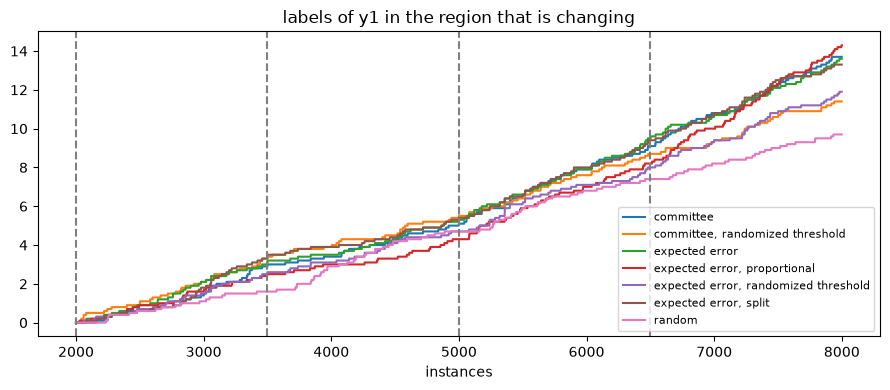

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, d in drifted.groupby("strategy"):
    labels = d[d["focus"] & d["queried"]].groupby("step").size() / len(SEEDS)
    labels = labels.reindex(range(WARMUP, N), fill_value=0).cumsum()
    ax.plot(labels, label=name)
for v in range(N_VISITS):
    ax.axvline(WARMUP + v * VISIT, color="grey", linestyle="--")
ax.set(xlabel="instances", title="labels of y1 in the region that is changing")
ax.legend(fontsize=8)
fig.tight_layout()

## Does it help?

Labels in the right place should give lower errors there. Since every setup sees the same
streams, each randomized setup can be compared to its deterministic strategy on each stream, and
random querying to expected error. A negative difference means a lower MAE. The standard error is
over the 10 streams, and `better` counts the streams on which the setup had the lower MAE. In the
region that is changing:

In [8]:
AGAINST = {
    "committee, randomized threshold": "committee",
    "expected error, randomized threshold": "expected error",
    "expected error, split": "expected error",
    "expected error, proportional": "expected error",
    "random": "expected error",
}


def compare(column):
    """Compare each setup to the one it is set against, stream by stream."""
    values = per_run[column].unstack("strategy")
    table = {}
    for name, against in AGAINST.items():
        diff = values[name] - values[against]
        table[name] = {
            "compared to": against,
            "difference": diff.mean(),
            "standard error": diff.std() / math.sqrt(len(diff)),
            "better": (diff < 0).sum(),
        }
    return pd.DataFrame.from_dict(table, orient="index")


compare("MAE in focus").round(3)

,compared to,difference,standard error,better
"committee, randomized threshold",committee,0.013,0.023,5
"expected error, randomized threshold",expected error,-0.009,0.022,5
"expected error, split",expected error,-0.007,0.023,6
"expected error, proportional",expected error,0.005,0.020,5
random,expected error,-0.005,0.023,4


Everywhere else on `y1`:

In [9]:
compare("MAE elsewhere").round(3)

,compared to,difference,standard error,better
"committee, randomized threshold",committee,-0.010,0.003,9
"expected error, randomized threshold",expected error,-0.011,0.003,10
"expected error, split",expected error,-0.001,0.003,5
"expected error, proportional",expected error,-0.012,0.002,10
random,expected error,-0.006,0.003,6


And on `y0` and `y2`, which do not drift:

In [10]:
compare("MAE on y0 and y2").round(3)

,compared to,difference,standard error,better
"committee, randomized threshold",committee,-0.007,0.003,8
"expected error, randomized threshold",expected error,-0.011,0.002,10
"expected error, split",expected error,-0.002,0.001,7
"expected error, proportional",expected error,-0.007,0.001,10
random,expected error,0.002,0.001,4


## Query probabilities

Randomized strategies log the probability with which each output was queried, in the
`probability` column of the log. Deterministic strategies log `NaN`. For `Proportional`, the
probabilities in and out of the region that is changing:

In [11]:
proportional = drifted[drifted["strategy"] == "expected error, proportional"]
proportional.groupby("focus")["probability"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
focus,,,,,,,,
False,58152.0,0.049,0.027,0.005,0.030,0.043,0.061,0.275
True,1848.0,0.078,0.045,0.006,0.042,0.068,0.104,0.274


Since every query has a known probability, the labels can be weighted by $1/p$ to correct for
the bias of active learning, which only labels the instances it chose (Beygelzimer et al., 2009).
`p_min` keeps these weights bounded. fishladder does not weight labels yet, but the log has what
it needs.

## Conclusions

- **Every active strategy found the drift.** They gave the region that was changing 3.8% to
  4.9% of the labels of `y1`, against 3.3% for random querying, which is the share of instances
  that fall in it. The deterministic strategies were not blind to it, most likely because the
  members of the committee disagree where new labels contradict old ones, and the error model of
  expected error predicts large errors around the few labels that revealed the change.
- **Finding it did not lower the error there.** With 5% of the labels, about 190 instances fall in
  the region during a run, and 10 to 14 of them are labelled, spread over four visits. No setup,
  randomized or not, had a measurably lower error in the region than the others.
- **Randomizing helped everywhere else**, by about 0.01 of MAE, or 5%, on almost every stream:
  the randomized threshold, with both strategies, and `Proportional`. The gain is almost as large on
  `y0` and `y2`, which do not drift, so it does not come from following the drift. Deterministic
  strategies concentrate their labels, and with models that only keep their last 200 labels, the
  rest of the space ends up underrepresented. Randomizing keeps the labelled instances closer to
  the stream while still favouring the useful ones, and did better on average than both
  deterministic and random querying.
- **`Split` did nothing measurable** here, since it only explores with a fifth of a small budget,
  1% of the instances.

On this stream, randomizing is worth it for what it does to the labelled sample rather than for
following the drift. Its effect on drift depends on how blind the deterministic strategy is, as
with classifiers whose confidence does not change with a drift far from their decision boundary,
and on whether the budget leaves enough labels for the region that changes. The setups above can
be reused to try other strategies, budgets and drifts.

## References

- Žliobaitė, I., Bifet, A., Pfahringer, B., & Holmes, G. (2014). Active learning with drifting
  streaming data. IEEE Transactions on Neural Networks and Learning Systems, 25(1), 27-39.
- Beygelzimer, A., Dasgupta, S., & Langford, J. (2009). Importance weighted active learning.
  Proceedings of the 26th International Conference on Machine Learning, 49-56.